# Xenium mouse kidney - ShamR

## Step 0 — Configuration

In [4]:
from pathlib import Path
import cellman.spatial as cms

ROOT       = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
XENIUM_DIR = f"{ROOT}/cellman_paper/data/xenium/ShamR-output-XETG00063__0005295__Region_6__20230717__191520"

STORE_ROOT = f"{ROOT}/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR"
ZARR       = f"{STORE_ROOT}/spatialdata.zarr"
CROPS      = f"{STORE_ROOT}/spatialdata_crops"
STORE      = f"{STORE_ROOT}/cellman_spatial"          # cellman zarr store (vf / clusters / maps)
SCRIPTS    = f"{ROOT}/CeLLMan/cellman/spatial/scripts"

DEVICE     = "cuda:1"            
NCORES     = 30

Path(STORE_ROOT).mkdir(parents=True, exist_ok=True)
print("cellman.spatial", cms.__version__, "| store:", STORE) 

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cellman.spatial 0.1.0 | store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial


## Step 1 — Load the Xenium sample into SpatialData

`spatialdata_io.xenium` reads the raw output directory (transcripts + morphology image)
into a `SpatialData` object, which is written to a zarr store for reuse.

In [4]:
import spatialdata as sd
import spatialdata_io

if Path(ZARR).exists():
    sdata = sd.read_zarr(ZARR)
    print("loaded existing", ZARR)
else:
    sdata = spatialdata_io.xenium(XENIUM_DIR)
    sdata.write(ZARR)
    print("wrote", ZARR)
sdata

/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the

wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (84419, 300)
with coordinate systems:
    ▸ 'global'

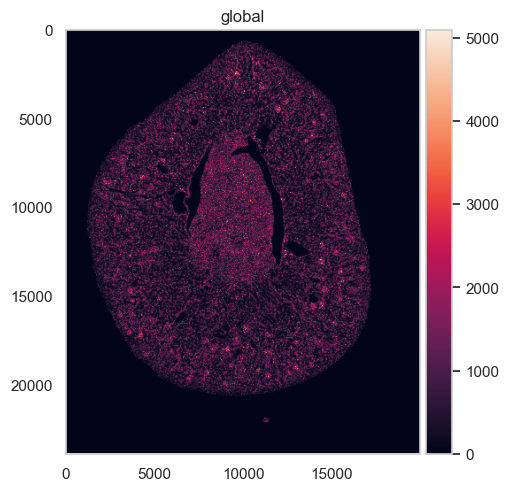

In [5]:
import spatialdata_plot 

IMAGE_KEY  = "morphology_mip"    
sdata.pl.render_images(IMAGE_KEY).pl.show()

## Step 2 — Tile the sample for chunked downsampling

`slice_spatialdata.py` splits the (large) image + transcripts into square tiles so
`downsample_vector(chunked=True, ...)` can stream them. Keeps only transcripts + image.

In [6]:
import subprocess, sys
if not Path(CROPS).exists():
    subprocess.run([sys.executable, f"{SCRIPTS}/slice_spatialdata.py",
                    "--sdata-path", ZARR,
                    "--tile-size", "10000",
                    "--output-dir", CROPS,
                    "--image-key", IMAGE_KEY,
                    "--keep-points", "transcripts",
                    "--drop-labels", "--drop-shapes", "--drop-tables"], check=True)
else:
    print("tiles already exist:", CROPS)

SDATA_PATH    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
TILE_SIZE     : 10000.0
OUTPUT_DIR    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops
MIN_TILE_SIZE : 5000.0
COORD_SYSTEM  : global

SpatialData loaded:
  images : ['morphology_focus', 'morphology_mip']
  labels : ['cell_labels', 'nucleus_labels']
  points : ['transcripts']
  shapes : ['cell_boundaries', 'nucleus_boundaries']
  tables : ['table']

Global extent: x=[0.00, 19971.00], y=[0.00, 23888.00]
x_edges: ['0.0', '10000.0', '19971.0']
y_edges: ['0.0', '10000.0', '23888.0']
Grid: 2 rows x 2 cols = 4 tiles

[0,0] x=[0.00,10000.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r00_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2760037, cells=0)
[0,1] x=[10000.00,19971.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r00_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2376664, cells=0)
[1,0] x=[0.00,10000.00], y=[10000.00,23888.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r01_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=4379602, cells=0)
[1,1] x=[10000.00,19971.00], y=[10000.00,23888.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r01_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=3597645, cells=0)

Done.
  Total grid cells : 4
  Tiles saved      : 4
  Tiles skipped    : 0
  Output directory : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops

Saved files:
  r00_c00.zarr
  r00_c01.zarr
  r01_c00.zarr
  r01_c01.zarr


## Step 3 — `downsample_vector` (transcript path)

Samples representative voxels from the morphology tissue mask and computes the KDE
vector field at each → `normalized_vectors` in the store.

- `revert_image=False`: Xenium morphology is bright-tissue-on-dark (threshold directly,
  no inversion). Use `True` for brightfield H&E.
- Transcript mode is automatic here: no precomputed blur field exists, so
  `downsample_vector` runs KDE-at-sampled-points (the count `grid=` argument is left unset).

In [7]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)

zarr keys: (empty)


In [8]:
adata = analysis.downsample_vector(
    chunked=True,
    sdata_dir=CROPS,
    n_samples=10,
    block_um=10,
    bandwidth=2.5,
    sampling_distance=1.0,
    image_key=IMAGE_KEY,
    revert_image=False,
    gpu_device=DEVICE,
) 

adata

downsample_vector (chunked): 4 sdata stores found.
  r00_c00: otsu=60
  r00_c01: otsu=56
  r01_c00: otsu=60
  r01_c01: otsu=58
  median otsu: 59.0

  [r00_c00]
    kept: 55,585  offset: [0.7139477133750916, 2.325871467590332, 0.0]

  [r00_c01]
    kept: 46,628  offset: [2125.000244140625, 1.1899898052215576, 0.0]

  [r01_c00]
    kept: 83,736  offset: [2.0103771686553955, 2125.00048828125, 0.0]

  [r01_c01]
    kept: 72,634  offset: [2125.00048828125, 2125.00048828125, 0.0]

  total kept (all chunks): 258,583


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=23, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


AnnData object with n_obs × n_vars = 258583 × 541
    obs: 'vf_norm'
    obsm: 'spatial'

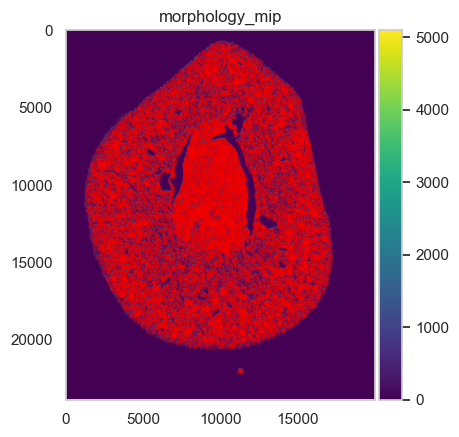

In [13]:
import matplotlib.pyplot as plt
POINTS_KEY = "transcripts"

ds.plot_image(sdata, image_key=IMAGE_KEY, cmap="viridis")
ds.extract_spatialdata_scale(sdata, element_name=POINTS_KEY)
ds.plot_downsampled_vector(s=0.01)
plt.show()

## Step 4 — `cluster_vectors` (Leiden)

Clusters the sampled vectors and **returns** an AnnData with `obs['leiden']`.
`cluster_vectors` no longer writes `ssam_clusters.h5ad` itself — we persist the
returned object so the external annotate-mode step can read it.

In [1]:
import scanpy as sc
adata = sc.read_h5ad('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial/mouse_kidney_cls.h5ad')
adata

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


AnnData object with n_obs × n_vars = 258583 × 541
    obs: 'vf_norm', 'leiden'
    uns: '__cellman_cluster_raw', 'leiden_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [2]:
del adata.obs['leiden']
del adata.uns['__cellman_cluster_raw']
del adata.uns['leiden_colors']
del adata.uns['neighbors']
del adata.uns['pca']
del adata.obsm['X_pca']
del adata.varm
del adata.obsp

adata

AnnData object with n_obs × n_vars = 258583 × 541
    obs: 'vf_norm'
    obsm: 'spatial'

In [5]:
STORE

'/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial'

In [6]:
adata.write_h5ad(f"{STORE}/mouse_kidney_cls.h5ad")

## Step 5 — Agentic annotation (external step)

Cluster → cell-type identity is assigned by the **annotate-mode** skill (LLM + Cell-Ontology
KG), which runs *outside* this notebook and writes
`annotation_out/ssam_clusters_annotated.h5ad` with `obs['celltype_annotation']`.

Run it against `ssam_clusters.h5ad` (mouse / kidney wing), then continue below.

/annotate-mode-v2 Annotate the h5ad files below using the mouse-kidney-expert agent.
Run each dataset as an INDEPENDENT agent IN PARALLEL — one agent per dataset, each with its
OWN --out directory.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial/mouse_kidney_cls.h5ad
- out   : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial
- tissue : mouse, kidney        
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- note : use 5090 GPU on device '1'

/tmp/ipykernel_152788/1454331831.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)


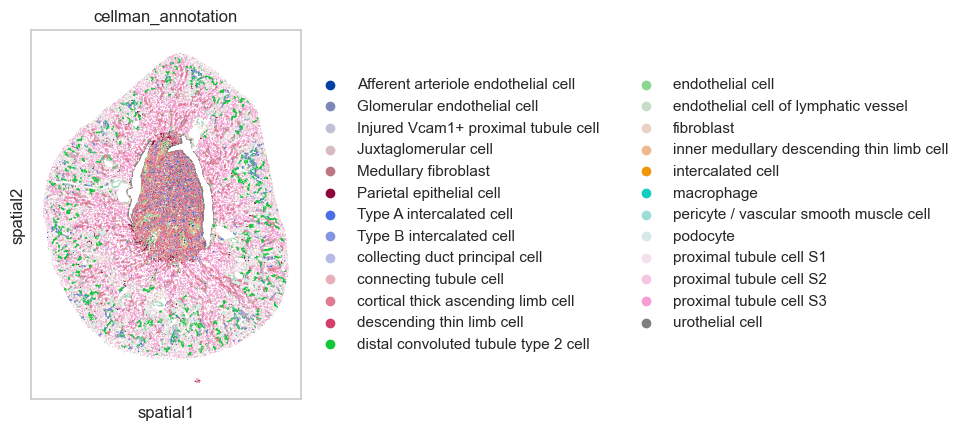

In [4]:
import scanpy as sc

ANNO = f"{STORE}/annotation_out/mouse_kidney_cls_annotated.h5ad"
if Path(ANNO).exists():
    anno = sc.read_h5ad(ANNO)
    sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)
else:
    anno = None
    print("annotation not found yet — run annotate-mode to produce:", ANNO)

## Step 6 — Merge annotated clusters → centroids

`merge_clusters.py` collapses the annotated clusters into final cell types and writes
`centroids` into the store (+ `merged_annotation.csv`) — the templates `map_celltypes` maps.

In [ ]:
subprocess.run([sys.executable, f"{SCRIPTS}/merge_clusters.py",
                "--store-dir", STORE,
                "--annotate-out", f"{STORE}/annotation_out",
                "--legacy"], check=True)

## Step 7 — `map_celltypes` (single entry point)

Builds the dense KDE vector field chunk-by-chunk and assigns every voxel to its
max-correlation centroid → `celltype_maps` + `max_correlations` in the store.

`map_celltypes` picks the **GPU** implementation automatically when a CUDA device is
available (`force_cpu=True` forces CPU). `method='corr'` is the default for transcript data.

In [ ]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)
sdata = sd.read_zarr(ZARR)

# ~20 min on GPU. Old API: analysis.map_celltypes_gpu(sdata, gpu_device=DEVICE)
analysis.map_celltypes(sdata, method="corr", gpu_device=DEVICE)

## Step 8 — Filter + plot the cell-type map

In [ ]:
analysis.filter_celltypemaps(min_r=0)
ds.extract_spatialdata_scale(sdata)

colors = anno.uns.get("celltype_annotation_colors") if anno is not None else None
# write the map into the SAME sdata: labels + RGB image + annotating table
ds.write_celltype_map(sdata, annotation_csv=f"{STORE}/merged_annotation.csv", colors=colors)
for _el in ("cellman_celltype_map", "cellman_celltype_map_rgb", "cellman_celltype"):
    sdata.write_element(_el, overwrite=True)   # persist outputs into the unified sdata zarr
ds.plot_celltypes_map(save_to_spatialdata=False, 
    show_annotation=True,
    annotation_csv=f"{STORE}/merged_annotation.csv",
    colors=colors,
)

In [5]:
ref = sc.read_h5ad(f"{ROOT}/cellman_paper/data/xenium/ref_shamR.h5ad")
ref

AnnData object with n_obs × n_vars = 85880 × 299
    obs: 'x_centroid', 'y_centroid', 'n_genes', 'n_counts', 'ident', 'region', 'celltype_plot', 'time', 'CN'
    uns: 'CN_colors', 'celltype_plot_colors', 'ident_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [7]:
anno

AnnData object with n_obs × n_vars = 258583 × 541
    obs: 'vf_norm', 'leiden', 'cellman_annotation'
    uns: '__cellman_cluster_raw', 'leiden_colors', 'neighbors', 'pca', 'cellman_annotation_colors'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

# Xenium mouse kidney - Day14R

## Step 0 — Configuration

In [1]:
from pathlib import Path
import cellman.spatial as cms

ROOT       = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
XENIUM_DIR = f"{ROOT}/cellman_paper/data/xenium/Day14R-output-XETG00063__0005161__Region_2__20230717__191519"

STORE_ROOT = f"{ROOT}/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R"
ZARR       = f"{STORE_ROOT}/spatialdata.zarr"
CROPS      = f"{STORE_ROOT}/spatialdata_crops"
STORE      = f"{STORE_ROOT}/cellman_spatial"          
SCRIPTS    = f"{ROOT}/CeLLMan/cellman/spatial/scripts"

DEVICE     = "cuda:1"            
NCORES     = 30

Path(STORE_ROOT).mkdir(parents=True, exist_ok=True)
print("cellman.spatial", cms.__version__, "| store:", STORE) 

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


cellman.spatial 0.1.0 | store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/cellman_spatial


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1 — Load the Xenium sample into SpatialData

`spatialdata_io.xenium` reads the raw output directory (transcripts + morphology image)
into a `SpatialData` object, which is written to a zarr store for reuse.

In [5]:
import spatialdata as sd
import spatialdata_io

if Path(ZARR).exists():
    sdata = sd.read_zarr(ZARR)
    print("loaded existing", ZARR)
else:
    sdata = spatialdata_io.xenium(XENIUM_DIR)
    sdata.write(ZARR)
    print("wrote", ZARR)
sdata

/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the

wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata.zarr


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 23891, 19954), (1, 11945, 9977), (1, 5972, 4988), (1, 2986, 2494), (1, 1493, 1247)
│     └── 'morphology_mip': DataTree[cyx] (1, 23891, 19954), (1, 11945, 9977), (1, 5972, 4988), (1, 2986, 2494), (1, 1493, 1247)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23891, 19954), (11945, 9977), (5972, 4988), (2986, 2494), (1493, 1247)
│     └── 'nucleus_labels': DataTree[yx] (23891, 19954), (11945, 9977), (5972, 4988), (2986, 2494), (1493, 1247)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (148234, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (148234, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (148234, 300)
with coordinate systems:
    ▸ 'glo

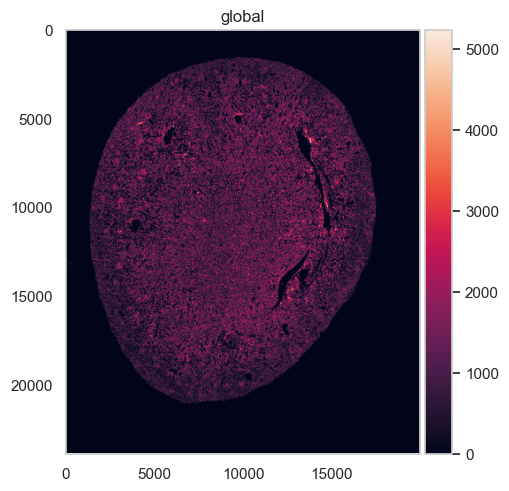

In [6]:
import spatialdata_plot 

IMAGE_KEY  = "morphology_mip"    
sdata.pl.render_images(IMAGE_KEY).pl.show()

## Step 2 — Tile the sample for chunked downsampling

`slice_spatialdata.py` splits the (large) image + transcripts into square tiles so
`downsample_vector(chunked=True, ...)` can stream them. Keeps only transcripts + image.

In [7]:
import subprocess, sys
if not Path(CROPS).exists():
    subprocess.run([sys.executable, f"{SCRIPTS}/slice_spatialdata.py",
                    "--sdata-path", ZARR,
                    "--tile-size", "10000",
                    "--output-dir", CROPS,
                    "--image-key", IMAGE_KEY,
                    "--keep-points", "transcripts",
                    "--drop-labels", "--drop-shapes", "--drop-tables"], check=True)
else:
    print("tiles already exist:", CROPS)

SDATA_PATH    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata.zarr
TILE_SIZE     : 10000.0
OUTPUT_DIR    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata_crops
MIN_TILE_SIZE : 5000.0
COORD_SYSTEM  : global

SpatialData loaded:
  images : ['morphology_focus', 'morphology_mip']
  labels : ['cell_labels', 'nucleus_labels']
  points : ['transcripts']
  shapes : ['cell_boundaries', 'nucleus_boundaries']
  tables : ['table']

Global extent: x=[0.00, 19954.00], y=[0.00, 23891.00]
x_edges: ['0.0', '10000.0', '19954.0']
y_edges: ['0.0', '10000.0', '23891.0']
Grid: 2 rows x 2 cols = 4 tiles

[0,0] x=[0.00,10000.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata_crops/r00_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=4464870, cells=0)
[0,1] x=[10000.00,19954.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata_crops/r00_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=3884267, cells=0)
[1,0] x=[0.00,10000.00], y=[10000.00,23891.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata_crops/r01_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=6523912, cells=0)
[1,1] x=[10000.00,19954.00], y=[10000.00,23891.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata_crops/r01_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=4332969, cells=0)

Done.
  Total grid cells : 4
  Tiles saved      : 4
  Tiles skipped    : 0
  Output directory : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/spatialdata_crops

Saved files:
  r00_c00.zarr
  r00_c01.zarr
  r01_c00.zarr
  r01_c01.zarr


## Step 3 — `downsample_vector` (transcript path)

Samples representative voxels from the morphology tissue mask and computes the KDE
vector field at each → `normalized_vectors` in the store.

- `revert_image=False`: Xenium morphology is bright-tissue-on-dark (threshold directly,
  no inversion). Use `True` for brightfield H&E.
- Transcript mode is automatic here: no precomputed blur field exists, so
  `downsample_vector` runs KDE-at-sampled-points (the count `grid=` argument is left unset).

In [8]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)

zarr keys: (empty)


In [9]:
adata = analysis.downsample_vector(
    chunked=True,
    sdata_dir=CROPS,
    n_samples=10,
    block_um=10,
    bandwidth=2.5,
    sampling_distance=1.0,
    image_key=IMAGE_KEY,
    revert_image=False,
    gpu_device=DEVICE,
) 

adata

downsample_vector (chunked): 4 sdata stores found.
  r00_c00: otsu=51
  r00_c01: otsu=48
  r01_c00: otsu=53
  r01_c01: otsu=48
  median otsu: 49.5

  [r00_c00]
    kept: 143,169  offset: [0.24979619681835175, 2.072844982147217, 0.0]

  [r00_c01]
    kept: 129,272  offset: [2125.00048828125, 0.700291633605957, 0.0]

  [r01_c00]
    kept: 212,707  offset: [1.705572485923767, 2125.000244140625, 0.0]

  [r01_c01]
    kept: 154,199  offset: [2125.000244140625, 2125.000244140625, 0.0]

  total kept (all chunks): 639,347


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=23, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


AnnData object with n_obs × n_vars = 639347 × 541
    obs: 'vf_norm'
    obsm: 'spatial'

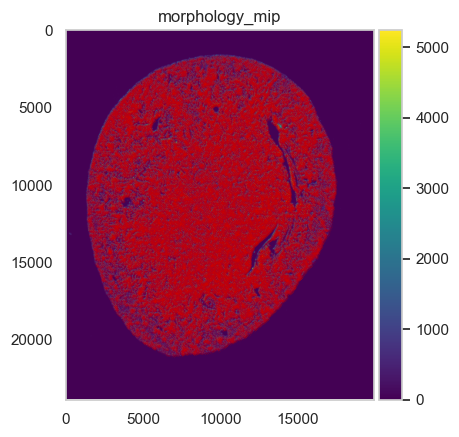

In [11]:
import matplotlib.pyplot as plt
POINTS_KEY = "transcripts"

ds.plot_image(sdata, image_key=IMAGE_KEY, cmap="viridis")
ds.extract_spatialdata_scale(sdata, element_name=POINTS_KEY)
ds.plot_downsampled_vector(s=0.001)
plt.show()

## Step 4 — `cluster_vectors` (Leiden)

Clusters the sampled vectors and **returns** an AnnData with `obs['leiden']`.
`cluster_vectors` no longer writes `ssam_clusters.h5ad` itself — we persist the
returned object so the external annotate-mode step can read it.

In [12]:
import rapids_singlecell as rsc
rsc.pp.pca(adata, n_comps=50)
rsc.pp.neighbors(adata, n_neighbors=30)
analysis.cluster_vectors(adata, outlier_detection_method=None, resolution=1)
adata

cluster_vectors: backend = rapids_singlecell (GPU)
Found 20 clusters


AnnData object with n_obs × n_vars = 639347 × 541
    obs: 'vf_norm', 'leiden'
    uns: 'pca', 'neighbors', '__cellman_cluster_raw'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

/tmp/ipykernel_4116922/1295171777.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color="leiden", spot_size=10)


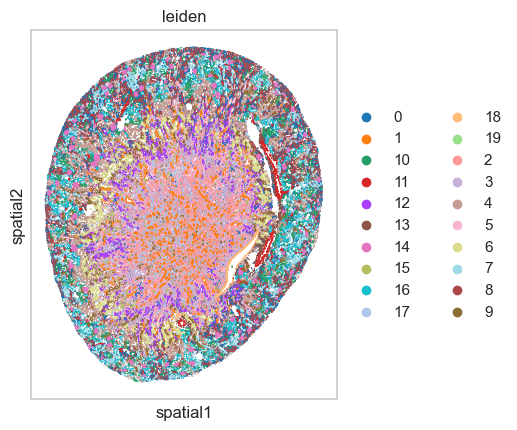

In [13]:
import scanpy as sc
sc.pl.spatial(adata, color="leiden", spot_size=10)

In [14]:
adata.write_h5ad(f"{STORE}/mouse_kidney_cls.h5ad")

## Step 5 — Agentic annotation (external step)

Cluster → cell-type identity is assigned by the **annotate-mode** skill (LLM + Cell-Ontology
KG), which runs *outside* this notebook and writes
`annotation_out/ssam_clusters_annotated.h5ad` with `obs['celltype_annotation']`.

Run it against `ssam_clusters.h5ad` (mouse / kidney wing), then continue below.

/annotate-mode-v2 Annotate the h5ad below using the mouse-kidney-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/cellman_spatial/mouse_kidney_cls.h5ad
- out : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/Day14R/cellman_spatial
- tissue : mouse, kidney          
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- cluster column : leiden
- subcluster-metric : euclidean             
- note : use 5090 GPU on device '1' 

In [ ]:
ANNO = f"{STORE}/annotation_out/ssam_clusters_annotated.h5ad"
if Path(ANNO).exists():
    anno = sc.read_h5ad(ANNO)
    sc.pl.spatial(anno, color="celltype_annotation", spot_size=10)
else:
    anno = None
    print("annotation not found yet — run annotate-mode to produce:", ANNO)

## Step 6 — Merge annotated clusters → centroids

`merge_clusters.py` collapses the annotated clusters into final cell types and writes
`centroids` into the store (+ `merged_annotation.csv`) — the templates `map_celltypes` maps.

In [ ]:
subprocess.run([sys.executable, f"{SCRIPTS}/merge_clusters.py",
                "--store-dir", STORE,
                "--annotate-out", f"{STORE}/annotation_out",
                "--legacy"], check=True)

## Step 7 — `map_celltypes` (single entry point)

Builds the dense KDE vector field chunk-by-chunk and assigns every voxel to its
max-correlation centroid → `celltype_maps` + `max_correlations` in the store.

`map_celltypes` picks the **GPU** implementation automatically when a CUDA device is
available (`force_cpu=True` forces CPU). `method='corr'` is the default for transcript data.

In [ ]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)
sdata = sd.read_zarr(ZARR)

# ~20 min on GPU. Old API: analysis.map_celltypes_gpu(sdata, gpu_device=DEVICE)
analysis.map_celltypes(sdata, method="corr", gpu_device=DEVICE)

## Step 8 — Filter + plot the cell-type map

In [ ]:
analysis.filter_celltypemaps(min_r=0)
ds.extract_spatialdata_scale(sdata)

colors = anno.uns.get("celltype_annotation_colors") if anno is not None else None
# write the map into the SAME sdata: labels + RGB image + annotating table
ds.write_celltype_map(sdata, annotation_csv=f"{STORE}/merged_annotation.csv", colors=colors)
for _el in ("cellman_celltype_map", "cellman_celltype_map_rgb", "cellman_celltype"):
    sdata.write_element(_el, overwrite=True)   # persist outputs into the unified sdata zarr
ds.plot_celltypes_map(save_to_spatialdata=False, 
    show_annotation=True,
    annotation_csv=f"{STORE}/merged_annotation.csv",
    colors=colors,
)